(sec-6-1)=
# 6.1 The Sampling Theorem

A computer stores an ECG as a list of measurements taken at regular time intervals. The heart's electrical activity continues between those measurements, so a natural question is: how closely must we sample to keep the changes we care about?

The sampling theorem answers that question under an ideal assumption: the signal contains no frequencies above a known limit. I will separate that ideal result from the choices we make in a real recorder. We will first connect sample indices to time, then work toward reconstruction and the role of an anti-aliasing filter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
import mne
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)
mne.set_log_level("ERROR")

(sec-6-1-1)=
## 6.1.1 From a Continuous Waveform to a Sequence of Numbers

A **sampler** reads the value of a continuous-time signal $x(t)$ at equally spaced instants $t = nT_s$, where $T_s$ is the **sampling period** in seconds and $n$ is an integer. The result is a discrete-time signal

$$
x[n] = x(nT_s), \qquad n = \ldots, -1, 0, 1, 2, \ldots
$$

The round brackets in $x(nT_s)$ refer to the continuous-time waveform evaluated at a time; the square brackets in $x[n]$ label the stored sample. At $f_s=360$ Hz, the sampling interval is $T_s=1/360$ s. Sample $n=180$ therefore represents the waveform at $180/360=0.5$ s. The index is a count, while $nT_s$ has units of seconds.

The **sampling rate** is $f_s = 1/T_s$ samples per second, quoted in hertz. A 12-lead ECG cart sampling at $f_s = 500$ Hz takes a sample every $T_s = 2$ ms; an EEG system at 256 Hz every 3.9 ms.

Square brackets mark the discrete index. Notice that $x[n]$ no longer carries any information about time in seconds: it is just a sequence of numbers, and the value of $T_s$ must be stored separately (in a WFDB record it sits in the header file). Two recordings with identical sample values but different sampling rates describe different physical signals.

The figure below shows the idea on one heartbeat from MIT-BIH Arrhythmia Database record 100 {cite:p}`moody2001,goldberger2000`. The record was digitized at 360 Hz, fast enough that the trace looks continuous at this scale, so I treat it as the "analog" waveform and sample it again at only 60 Hz by keeping every sixth value. I chose this rate deliberately low so that the individual samples are visible: the QRS complex, which lasts under 100 ms, is now described by only five or six numbers. Whether that is enough is exactly the question the sampling theorem answers.

In [2]:
rec = wfdb.rdrecord("../data/mitdb/100", channels=[0], sampfrom=360 * 10 + 60, sampto=360 * 11 + 60)
ecg_beat = rec.p_signal[:, 0]
fs_ecg = rec.fs
t_ecg = np.arange(ecg_beat.size) / fs_ecg

decim = 6                        # keep every 6th value: 360 Hz -> 60 Hz
n_s = np.arange(0, ecg_beat.size, decim)
t_s, x_s = t_ecg[n_s], ecg_beat[n_s]
print(f"Original rate: {fs_ecg} Hz, new rate: {fs_ecg / decim:.0f} Hz, Ts = {1000 * decim / fs_ecg:.1f} ms")
print(f"Samples kept in 1 s: {x_s.size}")

Original rate: 360 Hz, new rate: 60 Hz, Ts = 16.7 ms
Samples kept in 1 s: 60


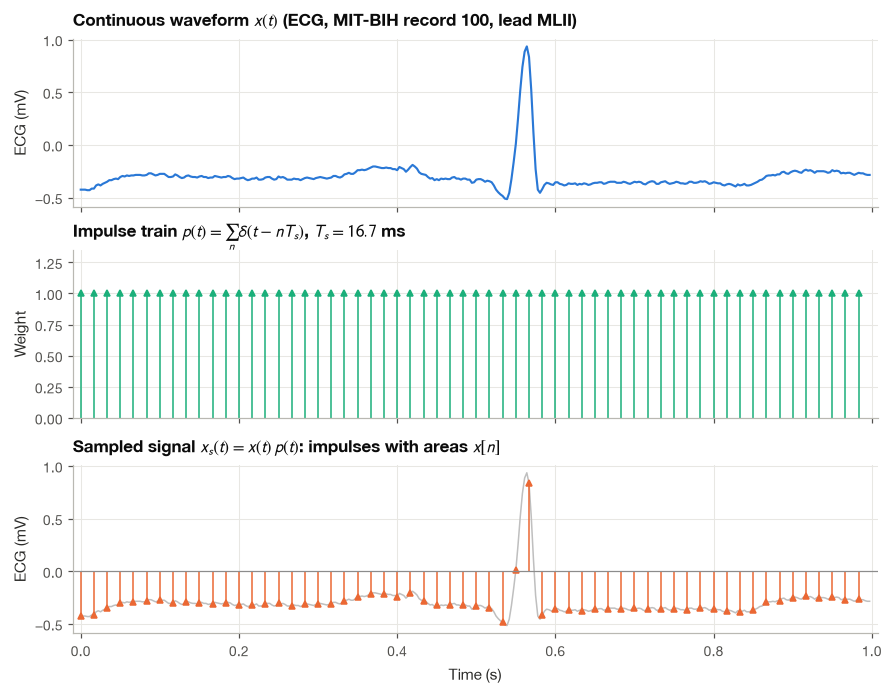

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(8, 6.2), sharex=True)
ax = axes[0]
ax.plot(t_ecg, ecg_beat, color=C[0])
ax.set(ylabel="ECG (mV)", title="Continuous waveform $x(t)$ (ECG, MIT-BIH record 100, lead MLII)")

ax = axes[1]
ax.vlines(t_s, 0, 1, color=C[2], lw=1.0)
ax.plot(t_s, np.ones_like(t_s), "^", color=C[2], ms=4)
ax.set(ylim=(0, 1.35), ylabel="Weight",
       title=r"Impulse train $p(t) = \sum_n \delta(t - nT_s)$, $T_s = 16.7$ ms")

ax = axes[2]
ax.plot(t_ecg, ecg_beat, color="0.75", lw=1)
ax.vlines(t_s, 0, x_s, color=C[1], lw=1.0)
ax.plot(t_s, x_s, "^", color=C[1], ms=4)
ax.axhline(0, color="0.55", lw=0.8)
ax.set(xlabel="Time (s)", ylabel="ECG (mV)",
       title=r"Sampled signal $x_s(t) = x(t)\,p(t)$: impulses with areas $x[n]$")
plt.show()

(sec-6-1-2)=
## 6.1.2 Ideal Sampling as Multiplication by an Impulse Train

To analyze sampling with the Fourier transform we need a continuous-time description of it. The trick is to keep the samples on the continuous time axis but squeeze each one into an impulse. Define the **impulse train** (sometimes called the Dirac comb)

$$
p(t) = \sum_{n=-\infty}^{\infty} \delta(t - nT_s),
$$

a row of unit impulses spaced $T_s$ apart, shown in the middle panel above. Multiplying the signal by it gives

$$
x_s(t) = x(t)\,p(t) = \sum_{n=-\infty}^{\infty} x(t)\,\delta(t - nT_s).
$$

Each term contains $x(t)$ multiplied by an impulse located at $nT_s$. An impulse is zero everywhere except at its location, so only the value of $x$ at that instant matters: $x(t)\,\delta(t - nT_s) = x(nT_s)\,\delta(t - nT_s)$. This is the sifting property of the delta function in its multiplicative form. Therefore

(eq-6-1)=
\begin{equation*}
x_s(t) = \sum_{n=-\infty}^{\infty} x[n]\,\delta(t - nT_s). \tag{6.1}
\end{equation*}

Equation [(6.1)](#eq-6-1) is the bridge between the two worlds. On the left is a continuous-time signal, to which every tool of Chapter 8 applies. On the right, the only information it contains is the sequence $x[n]$ (the impulse areas) and the spacing $T_s$. Whatever we learn about the spectrum of $x_s(t)$ is therefore a statement about what the samples can and cannot tell us.

Real converters do not produce impulses. A sample-and-hold circuit tracks the input, freezes it for a short time and lets the converter measure the frozen voltage. The impulse model idealizes the *measurement*: it says that the converter reads the signal at one instant and nothing else. The effects of holding the value for a finite time appear only when we convert back to an analog signal, which we study in Section 9.3.

(sec-6-1-3)=
## 6.1.3 The Spectrum of the Impulse Train

Throughout this chapter we write the Fourier transform with frequency in hertz,

$$
X(f) = \int_{-\infty}^{\infty} x(t)\,e^{-j2\pi f t}\,dt, \qquad x(t) = \int_{-\infty}^{\infty} X(f)\,e^{j2\pi f t}\,df,
$$

because sampling rates are naturally quoted in hertz and in this form the convolution theorem carries no factor of $2\pi$.

The impulse train is periodic with period $T_s$, so we can expand it in a complex Fourier series, exactly as in [Section 5.2](../ch07_fourier_series/index.md). The fundamental frequency of the series is $1/T_s = f_s$.

**Step 1: compute the Fourier coefficients.** For a periodic signal with period $T_s$, the coefficients are

$$
c_k = \frac{1}{T_s}\int_{-T_s/2}^{T_s/2} p(t)\,e^{-j2\pi k f_s t}\,dt.
$$

Over the interval $[-T_s/2, T_s/2]$ only the impulse at $t = 0$ is present. By the sifting property the integral picks out the value of $e^{-j2\pi k f_s t}$ at $t = 0$, which is 1:

$$
c_k = \frac{1}{T_s}\int_{-T_s/2}^{T_s/2} \delta(t)\,e^{-j2\pi k f_s t}\,dt = \frac{1}{T_s}\,e^{0} = \frac{1}{T_s} \qquad \text{for every } k.
$$

Every harmonic has the same weight. A train of infinitely narrow spikes contains all multiples of $f_s$ in equal amounts.

**Step 2: write the Fourier series.**

$$
p(t) = \sum_{k=-\infty}^{\infty} c_k\, e^{j2\pi k f_s t} = \frac{1}{T_s}\sum_{k=-\infty}^{\infty} e^{j2\pi k f_s t}.
$$

**Step 3: transform term by term.** The Fourier transform of a complex exponential $e^{j2\pi f_0 t}$ is an impulse $\delta(f - f_0)$ at its frequency. (To check this, take the inverse transform of $\delta(f - f_0)$: the sifting property gives $\int \delta(f - f_0)\,e^{j2\pi f t}\,df = e^{j2\pi f_0 t}$.) Applying this to each term with $f_0 = k f_s$,

(eq-6-2)=
\begin{equation*}
P(f) = \frac{1}{T_s}\sum_{k=-\infty}^{\infty} \delta(f - k f_s) = f_s \sum_{k=-\infty}^{\infty} \delta(f - k f_s). \tag{6.2}
\end{equation*}

An impulse train in time is an impulse train in frequency. The spacing is inverted: impulses every $T_s$ seconds become impulses every $f_s = 1/T_s$ hertz, each with area $f_s$. Sampling faster spreads the frequency-domain impulses further apart, a fact that will matter in a moment.

We can watch the series build up the impulse train. Keeping only the harmonics $|k| \le K$ gives the partial sum

$$
p_K(t) = \frac{1}{T_s}\sum_{k=-K}^{K} e^{j2\pi k f_s t} = \frac{1}{T_s}\left[1 + 2\sum_{k=1}^{K}\cos(2\pi k f_s t)\right],
$$

where we paired the terms $k$ and $-k$ using equation [(2.2)](../ch02_math_toolkit/01_complex_numbers.ipynb#eq-2-2) of [Section 2.1](../ch02_math_toolkit/01_complex_numbers.ipynb). At $t = nT_s$ every cosine equals 1 and the sum reaches $(2K+1)/T_s$; elsewhere the cosines disagree and largely cancel.

In [4]:
fs_demo = 4.0                         # Hz, so Ts = 0.25 s
Ts_demo = 1 / fs_demo
t = np.linspace(-0.6, 0.6, 4001)


def impulse_train_partial_sum(t, fs, K):
    """Fourier-series partial sum of the impulse train with harmonics |k| <= K."""
    k = np.arange(1, K + 1)
    return fs * (1 + 2 * np.cos(2 * np.pi * np.outer(t, k) * fs).sum(axis=1))


one_period = (t >= -Ts_demo / 2) & (t < Ts_demo / 2)
dt = t[1] - t[0]
for K in (2, 5, 20):
    pK = impulse_train_partial_sum(t, fs_demo, K)
    area = pK[one_period].sum() * dt
    print(f"K = {K:2d}: peak height = {pK.max():6.1f} (expected {(2 * K + 1) * fs_demo:5.1f}), "
          f"area over one period = {area:.3f}")

K =  2: peak height =   20.0 (expected  20.0), area over one period = 1.000
K =  5: peak height =   44.0 (expected  44.0), area over one period = 1.000
K = 20: peak height =  164.0 (expected 164.0), area over one period = 1.000


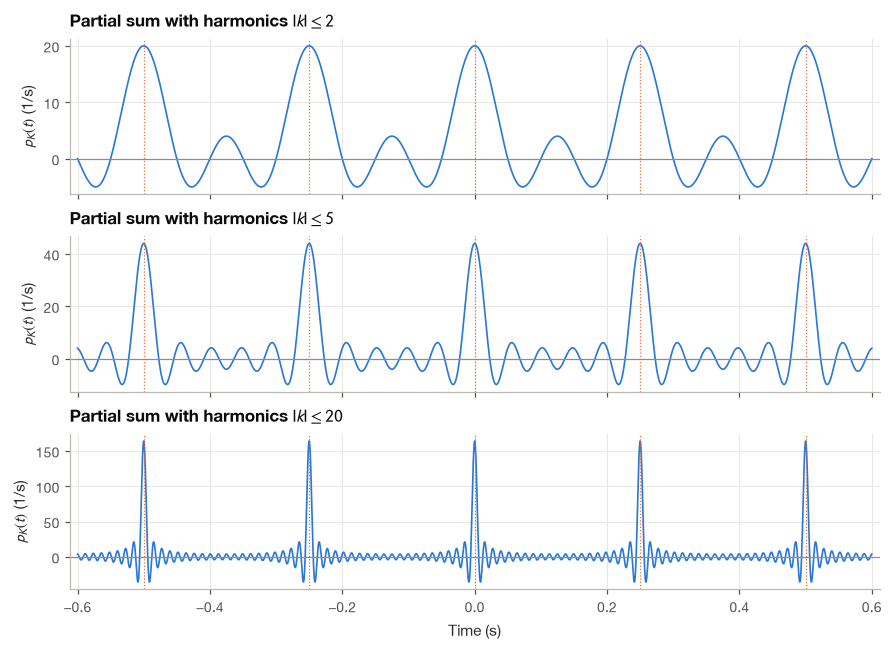

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(8, 5.8), sharex=True)
for ax, K, color in zip(axes, (2, 5, 20), (C[0], C[0], C[0])):
    ax.plot(t, impulse_train_partial_sum(t, fs_demo, K), color=color, lw=1.1)
    ax.axhline(0, color="0.55", lw=0.8)
    ax.set(ylabel="$p_K(t)$ (1/s)", title=f"Partial sum with harmonics $|k| \\leq {K}$")
    for n in range(-2, 3):
        ax.axvline(n * Ts_demo, color=C[1], lw=0.8, ls=":")
axes[-1].set_xlabel("Time (s)")
plt.show()

The peaks grow taller and narrower as $K$ increases while the area under each one stays equal to 1, which is exactly the behavior that defines an impulse. The dotted lines mark the sampling instants $nT_s$.

(sec-6-1-4)=
## 6.1.4 The Spectrum of a Sampled Signal

We now have everything needed to compute the spectrum of $x_s(t) = x(t)\,p(t)$. Multiplication in time corresponds to convolution in frequency (Section 8.3), so with frequency in hertz

$$
X_s(f) = (X * P)(f) = \int_{-\infty}^{\infty} X(\nu)\,P(f - \nu)\,d\nu .
$$

**Step 1: insert the impulse train spectrum.** Using equation [(6.2)](#eq-6-2) with $f$ replaced by $f - \nu$,

$$
X_s(f) = \int_{-\infty}^{\infty} X(\nu)\,\frac{1}{T_s}\sum_{k=-\infty}^{\infty}\delta(f - \nu - k f_s)\,d\nu .
$$

**Step 2: swap the sum and the integral.** Each term of the sum is an integral of $X(\nu)$ against a single impulse,

$$
X_s(f) = \frac{1}{T_s}\sum_{k=-\infty}^{\infty}\int_{-\infty}^{\infty} X(\nu)\,\delta\big(\nu - (f - k f_s)\big)\,d\nu ,
$$

where we used the fact that the delta function is even, $\delta(f - \nu - kf_s) = \delta(\nu - (f - kf_s))$.

**Step 3: apply the sifting property.** The impulse sits at $\nu = f - k f_s$, so each integral returns $X(f - k f_s)$:

(eq-6-3)=
\begin{equation*}
X_s(f) = \frac{1}{T_s}\sum_{k=-\infty}^{\infty} X(f - k f_s). \tag{6.3}
\end{equation*}

This is the central result of sampling theory. The spectrum of the sampled signal is the original spectrum, scaled by $1/T_s = f_s$, plus copies of it shifted to $\pm f_s$, $\pm 2f_s$, $\pm 3f_s$, and so on. The copies are called **replicas** or **images**. Sampling does not destroy the original spectrum; it adds infinitely many shifted versions of it. Whether the original can be recovered depends entirely on whether these replicas stay out of each other's way.

### A second expression for the same spectrum

There is another way to compute $X_s(f)$, directly from equation [(6.1)](#eq-6-1). The Fourier transform of a shifted impulse $\delta(t - t_0)$ is $e^{-j2\pi f t_0}$, so transforming [(6.1)](#eq-6-1) term by term gives

(eq-6-4)=
\begin{equation*}
X_s(f) = \sum_{n=-\infty}^{\infty} x[n]\,e^{-j2\pi f n T_s}. \tag{6.4}
\end{equation*}

Equation [(6.4)](#eq-6-4) uses only the samples, while [(6.3)](#eq-6-3) uses only the continuous spectrum, and the two must agree. Equation [(6.4)](#eq-6-4) is also the starting point of the discrete-time Fourier transform in Section 10.1: substitute $\Omega = 2\pi f T_s$ and it becomes $\sum_n x[n]e^{-j\Omega n}$. It shows at a glance that $X_s(f)$ is periodic in $f$ with period $f_s$, because replacing $f$ by $f + f_s$ multiplies each term by $e^{-j2\pi n} = 1$.

**Example 6.1.1.** A Gaussian pulse $x(t) = e^{-t^2/(2\sigma^2)}$ with $\sigma = 10$ ms is a rough model of a QRS complex. Its Fourier transform is again a Gaussian, $X(f) = \sigma\sqrt{2\pi}\,e^{-2\pi^2\sigma^2 f^2}$, which falls to $10^{-3}$ of its peak (60 dB down) near 59 Hz. Verify numerically that equations [(6.3)](#eq-6-3) and [(6.4)](#eq-6-4) give the same spectrum, for a fast rate ($f_s = 250$ Hz) and a slow one ($f_s = 50$ Hz).

The two sides of the identity are computed in completely different ways: one sums samples weighted by complex exponentials, the other sums shifted copies of the analytic spectrum. Both infinite sums are truncated where their terms become negligible.

In [6]:
sigma = 0.010                     # s, width of a QRS-like Gaussian pulse


def gauss_pulse(t):
    return np.exp(-t**2 / (2 * sigma**2))


def gauss_spectrum(f):
    """Continuous Fourier transform of gauss_pulse, frequency in Hz."""
    return sigma * np.sqrt(2 * np.pi) * np.exp(-2 * np.pi**2 * sigma**2 * f**2)


def sampled_spectrum_from_samples(f, fs, n_max=400):
    """Equation (9.4): sum of samples times complex exponentials."""
    n = np.arange(-n_max, n_max + 1)
    return np.exp(-2j * np.pi * np.outer(f, n) / fs) @ gauss_pulse(n / fs)


def sampled_spectrum_from_replicas(f, fs, k_max=60):
    """Equation (9.3): sum of shifted copies of the continuous spectrum."""
    k = np.arange(-k_max, k_max + 1)
    return fs * gauss_spectrum(f[:, None] - k[None, :] * fs).sum(axis=1)


f = np.linspace(-400, 400, 1601)
for fs in (250.0, 50.0):
    from_samples = sampled_spectrum_from_samples(f, fs)
    from_replicas = sampled_spectrum_from_replicas(f, fs)
    err = np.max(np.abs(from_samples - from_replicas)) / np.max(np.abs(from_replicas))
    print(f"fs = {fs:5.0f} Hz: max relative difference between (9.3) and (9.4) = {err:.1e}")
    print(f"             Ts*Xs(0) = {from_replicas[800].real / fs:.5f},  X(0) = {gauss_spectrum(0.0):.5f}")

fs =   250 Hz: max relative difference between (9.3) and (9.4) = 1.1e-15
             Ts*Xs(0) = 0.02507,  X(0) = 0.02507
fs =    50 Hz: max relative difference between (9.3) and (9.4) = 1.4e-15
             Ts*Xs(0) = 0.02543,  X(0) = 0.02507


The two expressions agree to machine precision at both rates, which confirms equation [(6.3)](#eq-6-3). The second printed line for each rate is more interesting. At 250 Hz the scaled sampled spectrum at $f = 0$ equals the true $X(0)$: the replicas centered on $\pm 250$ Hz contribute nothing there. At 50 Hz the value is larger than $X(0)$ because the neighboring replicas, centered on $\pm 50$ Hz, are wide enough to reach $f = 0$ and add their tails to it. The samples no longer carry the original spectrum alone.

(sec-6-1-5)=
## 6.1.5 The Sampling Theorem

The figure below draws equation [(6.3)](#eq-6-3) for a signal whose spectrum is strictly zero outside $|f| < B$, with $B = 40$ Hz. We plot $T_s X_s(f)$ so that the central replica has the same height as $X(f)$. With $f_s = 100$ Hz the replicas are separated by empty gaps. With $f_s = 60$ Hz each replica runs into its neighbors and the total, drawn in blue, no longer looks like $X(f)$ anywhere near the edges of the band.

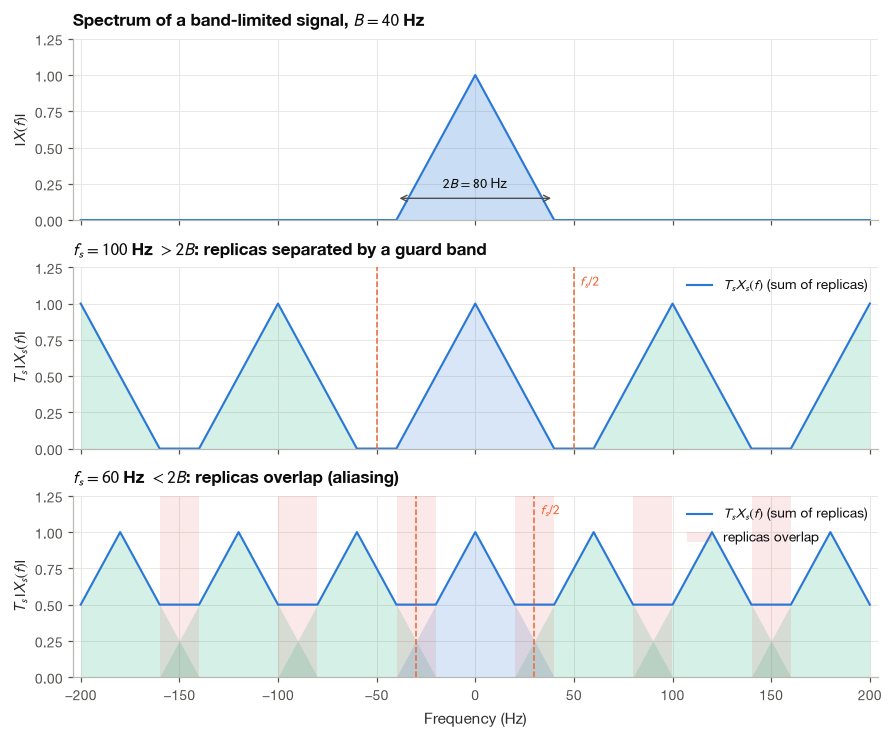

In [7]:
B = 40.0
f = np.linspace(-200, 200, 4001)


def triangle_spectrum(f):
    return np.clip(1 - np.abs(f) / B, 0, None)


fig, axes = plt.subplots(3, 1, figsize=(8, 6.6), sharex=True)
ax = axes[0]
ax.fill_between(f, triangle_spectrum(f), color=C[0], alpha=0.25, lw=0)
ax.plot(f, triangle_spectrum(f), color=C[0])
ax.annotate("", xy=(B, 0.15), xytext=(-B, 0.15), arrowprops=dict(arrowstyle="<->", color="0.3", lw=0.9))
ax.text(0, 0.2, "$2B = 80$ Hz", ha="center", va="bottom", fontsize=9)
ax.set(ylabel="$|X(f)|$", ylim=(0, 1.25), title="Spectrum of a band-limited signal, $B = 40$ Hz")

for ax, fs in zip(axes[1:], (100.0, 60.0)):
    total = np.zeros_like(f)
    n_active = np.zeros_like(f)
    for k in range(-5, 6):
        rep = triangle_spectrum(f - k * fs)
        total += rep
        n_active += rep > 0
        ax.fill_between(f, rep, color=C[0] if k == 0 else C[2], alpha=0.18, lw=0)
    ax.plot(f, total, color=C[0], lw=1.4, label=r"$T_s X_s(f)$ (sum of replicas)")
    for s in (-1, 1):
        ax.axvline(s * fs / 2, color=C[1], ls="--", lw=1)
    ax.text(fs / 2 + 3, 1.12, r"$f_s/2$", color=C[1], fontsize=9)
    if fs < 2 * B:
        ax.fill_between(f, 0, 1.25, where=n_active > 1, color=C[7], alpha=0.12, lw=0,
                        label="replicas overlap")
        title = f"$f_s = {fs:.0f}$ Hz $< 2B$: replicas overlap (aliasing)"
    else:
        title = f"$f_s = {fs:.0f}$ Hz $> 2B$: replicas separated by a guard band"
    ax.set(ylabel=r"$T_s\,|X_s(f)|$", ylim=(0, 1.25), title=title)
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Frequency (Hz)")
plt.show()

The geometry gives the condition for separation directly. The central replica occupies $-B < f < B$. The first replica on the right is the same shape shifted by $f_s$, so it occupies $f_s - B < f < f_s + B$. The two do not overlap when the left edge of the shifted copy lies to the right of the upper edge of the original,

(eq-6-5)=
\begin{equation*}
f_s - B > B \quad\Longleftrightarrow\quad f_s > 2B. \tag{6.5}
\end{equation*}

By symmetry the same inequality separates every pair of neighbors. When it holds, the interval $|f| < f_s/2$ contains the original spectrum and nothing else, and an ideal low-pass filter that keeps $|f| < f_s/2$ and multiplies by $T_s$ returns $X(f)$ exactly. Since $X(f)$ determines $x(t)$, the samples determine the signal. This is the **sampling theorem**:

> A signal whose Fourier transform is zero for $|f| \ge B$ is uniquely determined by its samples $x[n] = x(nT_s)$ provided the sampling rate satisfies $f_s > 2B$. It can be reconstructed from them by ideal low-pass filtering.

The explicit reconstruction formula, which turns the low-pass filter into a weighted sum of sinc functions, is derived in Section 9.3. When [(6.5)](#eq-6-5) fails, the replicas overlap and high-frequency content of one replica lands on top of low-frequency content of its neighbor. The sum cannot be untangled, and high frequencies masquerade as low ones. This is **aliasing**, the subject of [Section 6.2](02_aliasing.ipynb).

### Why the inequality is strict

Shannon's own formulation allows samples spaced exactly $1/(2B)$ apart {cite:p}`shannon1949`, and for finite-energy signals whose spectrum has no impulses that boundary case works. It fails as soon as the spectrum contains a pure sinusoid at the band edge, which is why I state the condition strictly as $f_s > 2B$ throughout the book. The classic counterexample takes $x(t) = \sin(2\pi f_0 t)$ and samples it at exactly $f_s = 2f_0$, so that $T_s = 1/(2f_0)$:

$$
x[n] = \sin\!\left(2\pi f_0 \cdot \frac{n}{2f_0}\right) = \sin(\pi n) = 0 \qquad \text{for every integer } n.
$$

The samples land on the zero crossings and the sinusoid vanishes without a trace. A general sinusoid at the same frequency fares little better. Using $\cos(\pi n + \varphi) = \cos(\pi n)\cos\varphi - \sin(\pi n)\sin\varphi$ and $\sin(\pi n) = 0$,

$$
A\cos\!\left(2\pi f_0 \frac{n}{2f_0} + \varphi\right) = A\cos(\pi n + \varphi) = A\cos\varphi\,\cos(\pi n) = (A\cos\varphi)\,(-1)^n .
$$

The samples depend on $A$ and $\varphi$ only through the product $A\cos\varphi$. Infinitely many sinusoids, with different amplitudes and phases, produce exactly the same samples, so the amplitude cannot be recovered. Sampling even slightly faster than $2f_0$ removes the ambiguity, at least in principle, because the sampling instants then drift slowly through the cycle and eventually catch the peaks.

In [8]:
f0 = 5.0                    # Hz
fs_crit = 2 * f0            # sampling exactly at twice the frequency
n = np.arange(0, 11)
tn = n / fs_crit

print(f"max |sin(2*pi*f0*n/(2 f0))| over 11 samples: {np.max(np.abs(np.sin(2 * np.pi * f0 * tn))):.1e}")
for A, phi in [(1.0, 0.0), (2.0, np.pi / 3), (np.sqrt(2), np.pi / 4)]:
    samples = A * np.cos(2 * np.pi * f0 * tn + phi)
    print(f"A = {A:.3f}, phi = {phi:.3f} rad -> first samples {np.round(samples[:4], 3)}")

max |sin(2*pi*f0*n/(2 f0))| over 11 samples: 1.2e-15
A = 1.000, phi = 0.000 rad -> first samples [ 1. -1.  1. -1.]
A = 2.000, phi = 1.047 rad -> first samples [ 1. -1.  1. -1.]
A = 1.414, phi = 0.785 rad -> first samples [ 1. -1.  1. -1.]


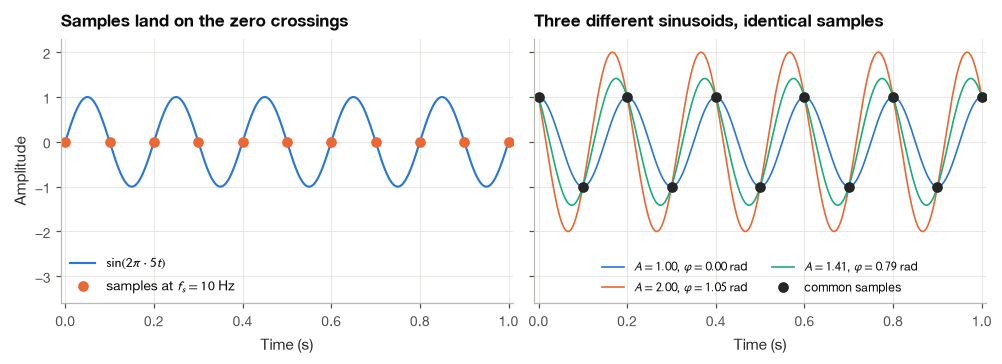

In [9]:
t_fine = np.linspace(0, 1.0, 2000)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
ax = axes[0]
ax.plot(t_fine, np.sin(2 * np.pi * f0 * t_fine), color=C[0], label=r"$\sin(2\pi\cdot 5t)$")
ax.plot(tn, np.sin(2 * np.pi * f0 * tn), "o", color=C[1], ms=6, label="samples at $f_s = 10$ Hz")
ax.set(xlabel="Time (s)", ylabel="Amplitude", title="Samples land on the zero crossings")
ax.legend(loc="lower left")

ax = axes[1]
for k, (A, phi) in enumerate([(1.0, 0.0), (2.0, np.pi / 3), (np.sqrt(2), np.pi / 4)]):
    ax.plot(t_fine, A * np.cos(2 * np.pi * f0 * t_fine + phi), color=C[k], lw=1.1,
            label=f"$A = {A:.2f}$, $\\varphi = {phi:.2f}$ rad")
ax.plot(tn, np.cos(np.pi * n), "o", color="0.15", ms=6, label="common samples")
ax.set(xlabel="Time (s)", ylim=(-3.6, 2.3), title="Three different sinusoids, identical samples")
ax.legend(loc="lower center", ncol=2, fontsize=8)
plt.show()

### Band-limited in theory, nearly band-limited in practice

A signal of finite duration can never be strictly band-limited: the Fourier transform of a time-limited pulse always has tails that extend to infinite frequency, as the Gaussian of Example 6.1.1 does. Physiological recordings start and stop, so strictly speaking none of them satisfies the hypothesis of the theorem. In practice $B$ is the frequency above which the remaining spectral content is too small to matter, typically because it lies below the noise floor of the amplifier or below the resolution of the converter (Section 9.4). An analog low-pass filter placed before the sampler, the **anti-aliasing filter**, enforces this by suppressing whatever lies above $B$. Choosing $B$, choosing $f_s$ and designing that filter are three faces of the same decision.

(sec-6-1-6)=
## 6.1.6 Nyquist Rate, Nyquist Frequency and a Little History

Two names are attached to the number 2 in equation [(6.5)](#eq-6-5), and they are easily confused.

- The **Nyquist rate** is $2B$, twice the highest frequency present in the *signal*. It is a property of the signal: the minimum sampling rate that the signal demands.
- The **Nyquist frequency** is $f_s/2$, half the sampling rate of the *system*. It is the highest frequency the system can represent without ambiguity, and it is also called the **folding frequency** for reasons that [Section 6.2](02_aliasing.ipynb) makes clear.

The sampling condition can be written either way: the sampling rate must exceed the Nyquist rate ($f_s > 2B$), or equivalently, the signal bandwidth must stay below the Nyquist frequency ($B < f_s/2$).

**Example 6.1.2.** The recordings of the MIT-BIH Arrhythmia Database were band-pass filtered between 0.1 and 100 Hz during digitization and sampled at 360 Hz {cite:p}`moody2001,goldberger2000`. (The rate is six times the 60 Hz mains frequency, which made it simple to implement digital 60 Hz notch filters.) Find the Nyquist rate of the filtered signal, the Nyquist frequency of the system and the width of the guard band between the top of the signal band and the bottom of the first replica.

With $B = 100$ Hz the Nyquist rate is $2B = 200$ Hz, comfortably below $f_s = 360$ Hz. The Nyquist frequency is $f_s/2 = 180$ Hz. The first replica starts at $f_s - B = 260$ Hz, so the empty guard band between the signal and its first image runs from 100 Hz to 260 Hz, a width of 160 Hz. That guard band is what allows the anti-aliasing filter to roll off gradually instead of cutting off like a brick wall.

The theorem has a long history. {cite:t}`nyquist1928`, studying telegraph transmission, showed that a channel of bandwidth $B$ can carry at most $2B$ independent pulse amplitudes per second, which is the same counting argument viewed from the transmitter's side. {cite:t}`shannon1949` stated the sampling theorem in its modern form, gave the interpolation formula, and made it a cornerstone of information theory. The same result had been found earlier by E. T. Whittaker in interpolation theory and by V. A. Kotelnikov in communication engineering, which is why it also carries their names in parts of the literature. {cite:t}`unser2000` tells the story and describes how the idea has been generalized since.

(sec-6-1-7)=
## 6.1.7 How Fast Should Biomedical Signals Be Sampled?

The table below collects typical choices. The rate is always set by the highest frequency we need to preserve, plus a margin that leaves room for a realistic anti-aliasing filter. Most systems sample at 2.5 to 5 times the upper edge of the band of interest rather than just above twice it.

| Signal | Band of interest | Typical $f_s$ | What sets the rate |
|---|---|---|---|
| Diagnostic 12-lead ECG | 0.05–150 Hz | 500–1000 Hz | 150 Hz upper cutoff recommended for adults (250 Hz for children) {cite:p}`kligfield2007` |
| Monitoring and Holter ECG | 0.5–40 Hz | 125–360 Hz | rhythm analysis only; storage and battery |
| ECG with pacemaker detection | pulses of about 0.1–1 ms | several kHz on a dedicated channel | the width of the pacing pulse, not the ECG bandwidth |
| Clinical scalp EEG | 0.5–70 Hz | 200–512 Hz | gamma activity, room for line-noise filtering |
| EEG high-frequency oscillations | 80–500 Hz | 2000 Hz or more | ripples and fast ripples in epilepsy |
| Surface EMG | 10–500 Hz | 1000–2048 Hz | most power lies between 20 and 250 Hz {cite:p}`merletti2004` |
| Needle EMG | about 10 Hz–10 kHz | 20 kHz or more | sharp motor unit potentials |
| PPG | 0.5–15 Hz | 25–125 Hz | pulse shape; higher for pulse timing |
| Respiration | 0.1–1 Hz | 10–50 Hz | breathing rate rarely exceeds 1 Hz |

I want to comment on two of the ECG rows, because the reason for the rate is not bandwidth in the usual sense.

**Pacemaker spikes.** An implanted pacemaker stimulates the heart with rectangular pulses typically 0.1 to 1 ms wide. Seen on the surface ECG they are tiny and very brief, much shorter than any natural ECG feature. At 500 Hz the samples are 2 ms apart, so a 0.5 ms pulse can fall entirely between two samples and disappear, exactly like the sinusoid of [Section 6.1.5](#sec-6-1-5) that hid between its samples. Even if one sample happens to catch it, the pulse's spectrum extends to several kilohertz, far above the 250 Hz Nyquist frequency. Monitors therefore detect pacing pulses in dedicated hardware or in a separate channel sampled at several kilohertz, and then mark the pulse on the slower diagnostic trace. A missed pacing spike matters clinically: it can make a paced rhythm look like an intrinsic one, or hide a pacemaker that captures intermittently.

**Beat timing.** The pulse waveform of a PPG has almost no content above 10–15 Hz, so 30 Hz would satisfy the sampling theorem. Yet heart rate variability and pulse arrival time require the *timing* of each beat to within a few milliseconds, and a peak located on a 40 ms grid is uncertain by up to half that interval unless interpolation is used. The same issue arises for R-peak detection in the ECG: the HRV Task Force recommends 250–500 Hz, accepting rates down to 100 Hz only when the R-peak position is refined by interpolation {cite:p}`taskforce1996`. Here the sampling rate is chosen to resolve time, not frequency, and I return to this point when we resample RR intervals in Section 9.3 and analyze them in Section 19.2.

(sec-6-1-8)=
## 6.1.8 How Much Bandwidth Does a Real ECG Occupy?

The table quotes bandwidths from guidelines and experience. I want to close the section by measuring the band directly on real recordings, starting with the ECG and then comparing it with the other signals. The tool is simple: estimate the power spectrum, add it up from 0 Hz upward, and read off the frequency below which a given fraction of the power lies.

### Step 1: Load five minutes of ECG and look at it

We read the first five minutes of lead MLII from MIT-BIH record 100 {cite:p}`moody2001,goldberger2000` and plot a few seconds to make sure the data are what we expect: a clean sinus rhythm at about 75 beats per minute.

In [10]:
fs_ecg = 360
ecg = wfdb.rdrecord("../data/mitdb/100", channels=[0], sampto=fs_ecg * 300).p_signal[:, 0]
t_ecg = np.arange(ecg.size) / fs_ecg
print(f"{ecg.size} samples = {ecg.size / fs_ecg:.0f} s at {fs_ecg} Hz, "
      f"range {ecg.min():.2f} to {ecg.max():.2f} mV")

108000 samples = 300 s at 360 Hz, range -0.69 to 1.25 mV


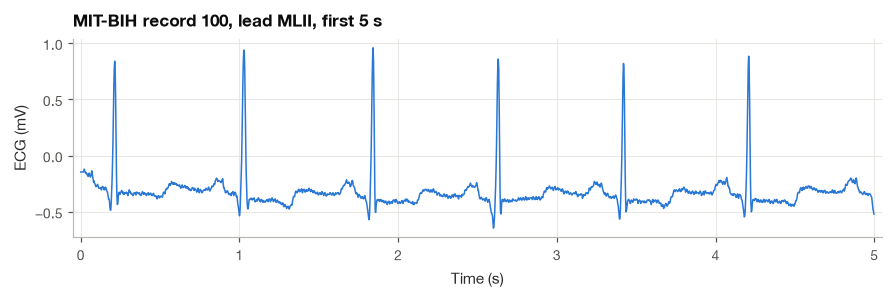

In [11]:
fig, ax = plt.subplots(figsize=(8, 2.6))
show = t_ecg < 5
ax.plot(t_ecg[show], ecg[show], color=C[0], lw=1)
ax.set(xlabel="Time (s)", ylabel="ECG (mV)", title="MIT-BIH record 100, lead MLII, first 5 s")
plt.show()

### Step 2: Estimate the spectrum and accumulate the power

The function below estimates the power spectrum with Welch's method (developed properly in [Section 7.3](../ch12_spectral_estimation/index.md); here it simply gives a smooth spectrum with 4 s segments, so a resolution of 0.25 Hz), removes the mean first so that the DC offset does not count as signal power, accumulates the spectrum from 0 Hz upward and reports the frequencies below which 90%, 99% and 99.9% of the power lies.

In [12]:
def power_bandwidth(x, fs, seg_seconds, fractions=(0.90, 0.99, 0.999)):
    """Frequencies below which the given fractions of the mean-removed signal power lie."""
    f, P = signal.welch(x - x.mean(), fs, nperseg=int(seg_seconds * fs))
    cum = np.cumsum(P) / P.sum()
    return f, P, cum, [f[np.searchsorted(cum, q)] for q in fractions]


f_e, P_e, cum_e, bw_e = power_bandwidth(ecg, fs_ecg, 4.0)
for q, b in zip((90, 99, 99.9), bw_e):
    print(f"{q:5.1f}% of the ECG power lies below {b:6.2f} Hz")

 90.0% of the ECG power lies below  25.75 Hz
 99.0% of the ECG power lies below  43.75 Hz
 99.9% of the ECG power lies below  67.75 Hz


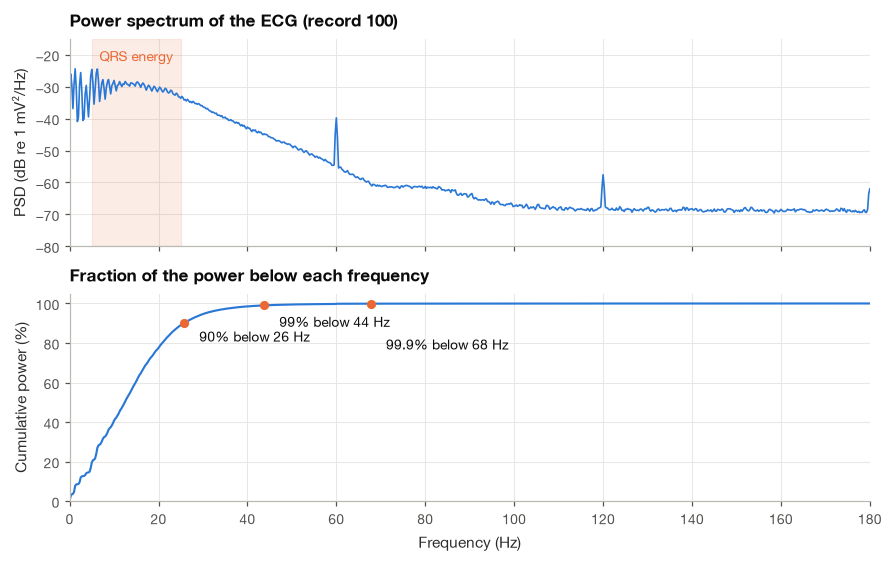

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.0), sharex=True)
ax = axes[0]
ax.plot(f_e, 10 * np.log10(P_e), color=C[0], lw=1.1)
ax.axvspan(5, 25, color=C[1], alpha=0.12)
ax.text(15, -22, "QRS energy", ha="center", fontsize=9, color=C[1])
ax.set(ylabel="PSD (dB re 1 mV$^2$/Hz)", ylim=(-80, -15), title="Power spectrum of the ECG (record 100)")
ax = axes[1]
ax.plot(f_e, 100 * cum_e, color=C[0])
for q, b, dy in zip((90, 99, 99.9), bw_e, (-12, -14, -30)):
    ax.plot(b, q, "o", color=C[1], ms=5)
    ax.annotate(f"{q:g}% below {b:.0f} Hz", (b, q), textcoords="offset points", xytext=(10, dy), fontsize=9)
ax.set(xlabel="Frequency (Hz)", ylabel="Cumulative power (%)", xlim=(0, 180), ylim=(0, 105),
       title="Fraction of the power below each frequency")
plt.show()

The spectrum is dominated by the band from about 1 to 30 Hz, where the P and T waves and above all the QRS complex live, and then falls by more than 30 dB toward 100 Hz. The narrow spike at 60 Hz is a trace of power-line interference, which Section 10.5 examines in detail. Ninety-nine percent of the power lies below about 44 Hz.

### Step 3: Repeat the measurement for other biosignals

For comparison we apply the same function to one minute of eyes-closed occipital EEG from the EEG Motor Movement/Imagery Dataset {cite:p}`schalk2004`, eight minutes of PPG from BIDMC record 1 {cite:p}`pimentel2017`, and 12.7 s of healthy needle EMG from the PhysioNet EMG examples {cite:p}`goldberger2000`. The segment length is adapted to each signal so that every estimate has many averaged segments.

In [14]:
raw = mne.io.read_raw_edf("../data/eegmmidb/S001R02.edf", preload=True)
mne.datasets.eegbci.standardize(raw)
eeg = raw.get_data(picks=["Oz"])[0] * 1e6
rec = wfdb.rdrecord("../data/bidmc/bidmc01")
ppg = rec.p_signal[:, [s.strip(",") for s in rec.sig_name].index("PLETH")]
emg = wfdb.rdrecord("../data/emgdb/emg_healthy").p_signal[:, 0]

recordings = {"ECG (MIT-BIH 100, MLII)": (ecg, 360, 4.0),
              "EEG (eyes closed, Oz)": (eeg, 160, 4.0),
              "PPG (BIDMC 01)": (ppg, 125, 8.0),
              "Needle EMG (healthy)": (emg, 4000, 0.5)}

rows, curves = [], {}
for name, (x, fs, seg) in recordings.items():
    f, _, cum, bws = power_bandwidth(x, fs, seg)
    curves[name] = (f, cum)
    rows.append({"recording": name, "fs (Hz)": fs, "Nyquist (Hz)": fs / 2,
                 "90% (Hz)": bws[0], "99% (Hz)": bws[1], "99.9% (Hz)": bws[2]})
bandwidths = pd.DataFrame(rows)
print(bandwidths.to_string(index=False))

              recording  fs (Hz)  Nyquist (Hz)  90% (Hz)  99% (Hz)  99.9% (Hz)
ECG (MIT-BIH 100, MLII)      360         180.0    25.750     43.75      67.750
  EEG (eyes closed, Oz)      160          80.0    16.000     29.00      46.500
         PPG (BIDMC 01)      125          62.5     3.125      4.75       9.125
   Needle EMG (healthy)     4000        2000.0   394.000   1666.00    1922.000


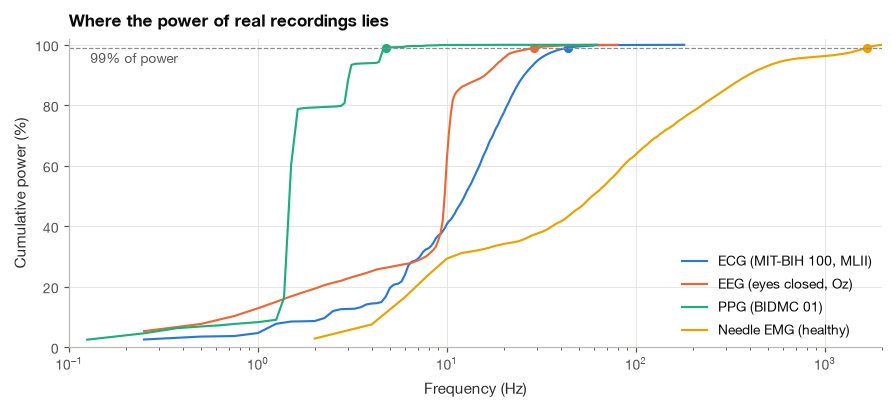

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, (name, (f, cum)) in enumerate(curves.items()):
    ax.semilogx(f[1:], 100 * cum[1:], color=C[k], label=name)
    ax.plot(rows[k]["99% (Hz)"], 99, "o", color=C[k], ms=5)
ax.axhline(99, color="0.55", lw=0.8, ls="--")
ax.text(0.13, 94, "99% of power", fontsize=9, color="0.35")
ax.set(xlabel="Frequency (Hz)", ylabel="Cumulative power (%)", xlim=(0.1, 2000), ylim=(0, 102),
       title="Where the power of real recordings lies")
ax.legend(loc="lower right")
plt.show()

### Step 4: Compare the energy bandwidth with the diagnostic bandwidth

The numbers confirm the orders of magnitude in the table: 99% of the PPG power lies below about 5 Hz, of the EEG below 30 Hz and of the ECG below 45 Hz, while the needle EMG still has measurable power close to the 2 kHz Nyquist frequency of its recording, a hint that 4 kHz is on the low side for needle EMG.

They also show why I distrust an *energy* bandwidth as a guide to the sampling rate of an ECG. By the 99.9% criterion the ECG would need only about 70 Hz, yet clinical guidelines ask for 150 Hz {cite:p}`kligfield2007`. The extra band carries very little energy but shapes the sharp corners of the QRS complex, small notches and slurs within it, and the amplitude of narrow features; cutting it reduces measured R-wave amplitudes, particularly in children, whose QRS complexes are shorter. (The MIT-BIH recordings were themselves band-limited to 100 Hz before digitization, so they cannot show what lies beyond.) The sampling rate must protect the information we care about, and that information is not always where most of the energy is. [Section 11.2](../ch17_ecg/index.md) makes this concrete by re-digitizing an ECG at several rates and measuring what happens to QRS amplitude and R-peak timing.

```{note}
When you inherit a dataset, read its sampling rate *and* the analog filter settings from the documentation before choosing an analysis. A 128 Hz Holter recording can support rhythm analysis but not late-potential or pacemaker analysis, however carefully it is processed afterwards. No algorithm can recover information that the sampler discarded.
```

## Summary

Sampling can be modeled as multiplication of the continuous signal by an impulse train, which turns the sequence of samples into a continuous-time signal $x_s(t) = \sum_n x[n]\,\delta(t - nT_s)$ that Fourier analysis can handle. The impulse train has a Fourier series with equal coefficients $1/T_s$, so its spectrum is another impulse train with spacing $f_s$. By the convolution theorem, the spectrum of the sampled signal is the original spectrum replicated at every multiple of $f_s$ and scaled by $1/T_s$, equation [(6.3)](#eq-6-3). If the signal is band-limited to $|f| < B$ and $f_s > 2B$, the replicas do not overlap, an ideal low-pass filter isolates the original spectrum, and the samples determine the signal completely. The strict inequality matters: a sinusoid sampled at exactly twice its frequency can produce all-zero samples.

The Nyquist rate $2B$ belongs to the signal and the Nyquist frequency $f_s/2$ to the sampling system. Real signals are only approximately band-limited, so practical systems sample at a comfortable multiple of the band of interest and rely on an anti-aliasing filter. [Section 6.2](02_aliasing.ipynb) examines what happens when replicas overlap and how such filters are designed, Section 9.3 derives the reconstruction formula and shows how to change the sampling rate of a recording, and Section 9.4 turns to the other half of digitization, the rounding of each sample to a finite number of bits.

## Exercises

1. A signal is $x(t) = 2\cos(2\pi\,40t) + \sin(2\pi\,65t)\cos(2\pi\,20t)$, with $t$ in seconds. Expand the product into a sum of sinusoids, find the highest frequency present, and state the Nyquist rate. Would $f_s = 160$ Hz be sufficient?
2. Using equation [(6.3)](#eq-6-3), sketch the spectrum of $x_s(t)$ for $x(t) = \cos(2\pi\,30t)$ sampled at $f_s = 100$ Hz and at $f_s = 50$ Hz. Mark all impulses between $-150$ Hz and $150$ Hz. In the second case, which impulse inside $|f| < 25$ Hz would a low-pass filter pass, and what frequency would it appear to have?
3. Show that if $x(t) = A\cos(2\pi f_0 t + \varphi)$ is sampled at $f_s = 2f_0$ starting at an arbitrary time offset $t_0$ (samples at $t_0 + nT_s$), the samples still have the form $c\,(-1)^n$. Express $c$ in terms of $A$, $\varphi$ and $t_0$ and explain why no choice of $t_0$ removes the ambiguity in principle.
4. Repeat the numerical verification of Example 6.1.1 for the two-sided exponential pulse $x(t) = e^{-|t|/\tau}$ with $\tau = 20$ ms, whose transform is $X(f) = 2\tau/(1 + (2\pi f\tau)^2)$. Plot $|T_s X_s(0) - X(0)|/X(0)$ as a function of $f_s$ from 50 Hz to 2 kHz on a log–log scale. Why does the error never become exactly zero, and how fast does it decrease compared with the Gaussian pulse?
5. Apply `power_bandwidth` to the three EMG recordings (`emg_healthy`, `emg_myopathy`, `emg_neuropathy`) and to MIT-BIH record 105, which is very noisy. Rank them by their 99% bandwidth and relate the differences to physiology (short, polyphasic motor unit potentials in myopathy) and to the noise in record 105.
6. (Band-pass sampling.) A signal occupies only the band $1000 < |f| < 1100$ Hz. Using equation [(6.3)](#eq-6-3), show that sampling at $f_s = 220$ Hz, far below $2 \times 1100$ Hz, produces replicas that do not overlap, and find another rate below 2200 Hz that fails. Then verify your answer numerically by sampling a sum of sinusoids at 1010, 1050 and 1090 Hz.

## Further Reading

The derivation through the impulse train follows the standard treatment in {cite:t}`oppenheim2010` (Chapter 3) and {cite:t}`oppenheim1997` (Chapter 5), where the reconstruction and decimation problems are also developed. {cite:t}`shannon1949` is short and still very readable, and {cite:t}`unser2000` gives a modern perspective, including sampling with non-ideal kernels. For the choice of ECG bandwidth and its clinical consequences, see the recommendations of {cite:t}`kligfield2007`; {cite:t}`webster2010` covers the analog front ends that precede the sampler.